In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [4]:
import os

ARQUIVO = 'tabela_final.csv'
ID_TABELA_FINAL = '13ZcWd_wD4lIFMPi_YI0ba0xjUCMTr4tb'  # tabela_final.csv no Drive do projeto

# Se a tabela não estiver na sessão, baixa direto do Google Drive
# (na primeira vez o Colab pede autorização da conta Google)
if not os.path.exists(ARQUIVO):
    from google.colab import auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload

    auth.authenticate_user()
    servico = build('drive', 'v3')
    pedido = servico.files().get_media(fileId=ID_TABELA_FINAL)

    with open(ARQUIVO, 'wb') as f:
        baixador = MediaIoBaseDownload(f, pedido)
        concluido = False
        while not concluido:
            _, concluido = baixador.next_chunk()

df = pd.read_csv(ARQUIVO)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 8 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Ano_do_Censo                             4009 non-null   int64  
 1   Nome_do_Municipio                        4009 non-null   object 
 2   Codigo_da_Escola                         4009 non-null   int64  
 3   Nome_da_Escola                           4009 non-null   object 
 4   Quantidade_de_Matriculados_Ensino_Medio  4009 non-null   float64
 5   Aprovacao_EM_Total                       4009 non-null   float64
 6   Reprovacao_EM_Total                      4009 non-null   float64
 7   Abandono_EM_Total                        4009 non-null   float64
dtypes: float64(4), int64(2), object(2)
memory usage: 250.7+ KB


In [6]:
#checando se há valores nulos
df.isna().sum()

,0
Ano_do_Censo,0
Nome_do_Municipio,0
Codigo_da_Escola,0
Nome_da_Escola,0
Quantidade_de_Matriculados_Ensino_Medio,0
Aprovacao_EM_Total,0
Reprovacao_EM_Total,0
Abandono_EM_Total,0


In [7]:
#checando se há duplicatas
df.duplicated().sum()

np.int64(0)

In [8]:
#checando os valores únicos
df['Ano_do_Censo'].unique()


array([2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2015, 2016, 2025])

In [9]:
df.describe()

,Ano_do_Censo,Codigo_da_Escola,Quantidade_de_Matriculados_Ensino_Medio,Aprovacao_EM_Total,Reprovacao_EM_Total,Abandono_EM_Total
count,4009.000000,4.009000e+03,4009.000000,4009.000000,4009.000000,4009.000000
mean,2020.007234,3.309524e+07,513.982040,77.664405,14.790422,7.545173
std,3.165621,5.549851e+04,520.913534,13.176567,9.987367,8.331654
min,2015.000000,3.305188e+07,2.000000,0.000000,0.000000,0.000000
25%,2017.000000,3.307159e+07,162.000000,68.500000,7.200000,0.700000
50%,2020.000000,3.308643e+07,294.000000,77.900000,14.100000,5.200000
75%,2023.000000,3.310464e+07,671.000000,87.600000,20.800000,11.500000
max,2025.000000,3.355823e+07,2805.000000,100.000000,80.600000,100.000000


In [21]:
variaveis_alvo = [
    "Quantidade_de_Matriculados_Ensino_Medio",
    "Aprovacao_EM_Total",
    "Reprovacao_EM_Total",
    "Abandono_EM_Total"
]
dados_para_zscore = df[variaveis_alvo]

# 1. Calcula o Z-score (lida automaticamente com valores nulos/NaNs)
zscores = (dados_para_zscore - dados_para_zscore.mean()) / dados_para_zscore.std()

# 2. Adiciona o sufixo '_zscore' no nome das colunas geradas
zscores.columns = [f"{col}_zscore" for col in zscores.columns]

# 3. Junta as colunas de Z-score ao DataFrame original
df_dados_com_zscore = pd.concat([df, zscores], axis=1)

# Visualizar o resultado
display(df_dados_com_zscore.head())

,Ano_do_Censo,Nome_do_Municipio,Codigo_da_Escola,Nome_da_Escola,Quantidade_de_Matriculados_Ensino_Medio,Aprovacao_EM_Total,Reprovacao_EM_Total,Abandono_EM_Total,Quantidade_de_Matriculados_Ensino_Medio_zscore,Aprovacao_EM_Total_zscore,Reprovacao_EM_Total_zscore,Abandono_EM_Total_zscore
0,2017,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,584.0,69.9,19.2,10.9,0.134414,-0.589259,0.441516,0.402660
1,2018,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,476.0,64.3,31.8,3.9,-0.072914,-1.014255,1.703109,-0.437509
2,2019,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,435.0,70.4,16.7,12.9,-0.151622,-0.551312,0.191199,0.642709
3,2020,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,379.0,97.6,0.0,2.4,-0.259126,1.512958,-1.480913,-0.617545
4,2021,SÃO GONÇALO,33051879,CE DOUTOR MOACYR MEIRELLES PADILHA,382.0,94.3,5.2,0.5,-0.253367,1.262514,-0.960255,-0.845591


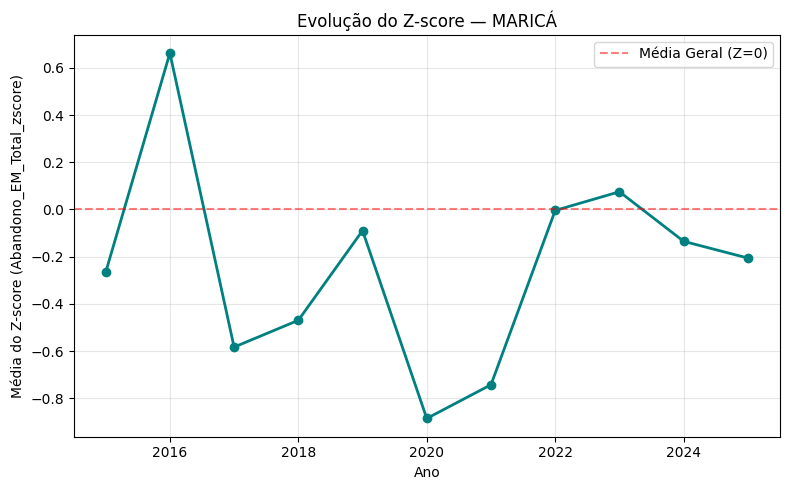

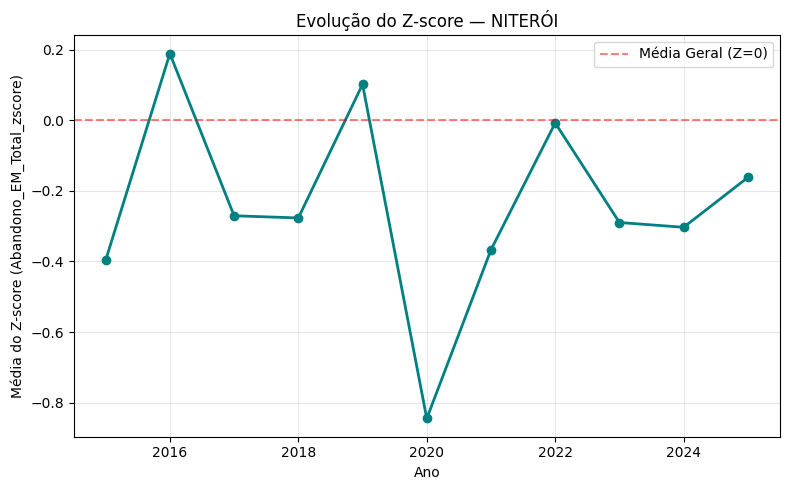

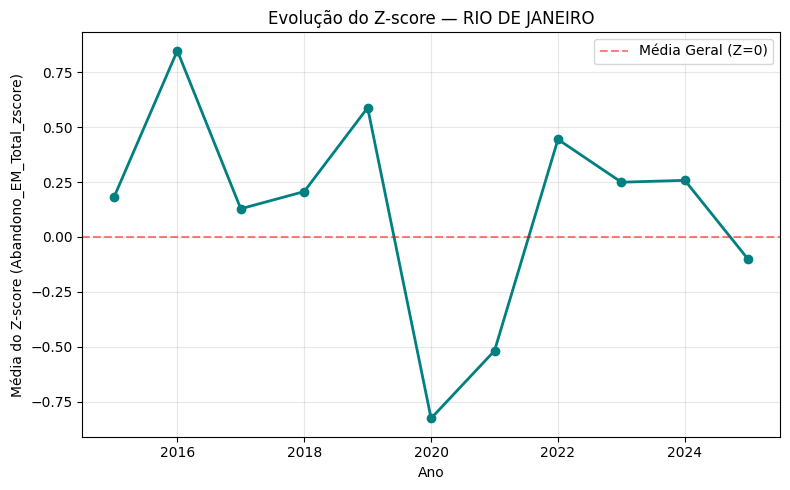

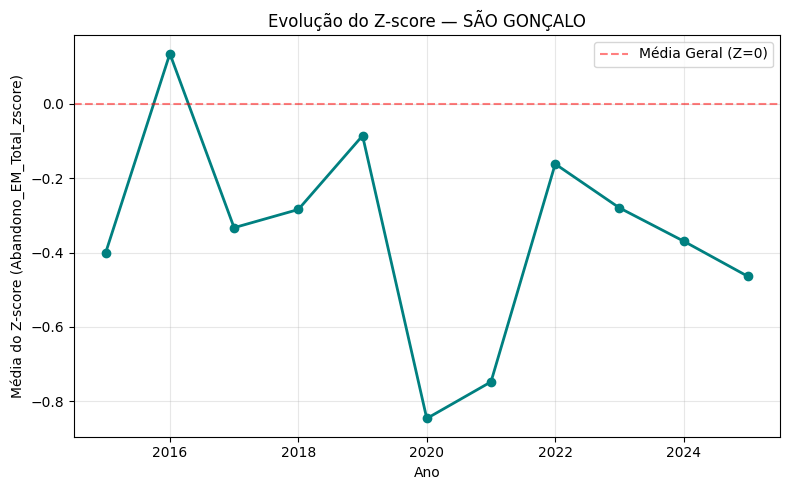

In [25]:
import pandas as pd
import matplotlib.pyplot as plt


colunas_numericas = df.select_dtypes(include=['number'])

# Calcular Z-scores e renomear colunas
zscores = (colunas_numericas - colunas_numericas.mean()) / colunas_numericas.std()
zscores.columns = [f"{col}_zscore" for col in zscores.columns]

# Juntar ao DataFrame original criando a variável exata que o erro apontou
teste_com_zscore = pd.concat([df, zscores], axis=1)


# 2. GERAR OS GRÁFICOS
# Identificar as colunas de Z-score
colunas_zscore = [col for col in teste_com_zscore.columns if col.endswith('_zscore')]

variavel_zscore = colunas_zscore[5]

# Agrupar por Município e Ano
colunas_selecionadas = ['Nome_do_Municipio', 'Ano_do_Censo', variavel_zscore]

zscore_ano_municipio = (
    teste_com_zscore[colunas_selecionadas]
    .groupby(['Nome_do_Municipio', 'Ano_do_Censo'])
    .mean()
    .reset_index()
)

# Escolher os primeiros 5 municípios para teste
municipios_alvo = zscore_ano_municipio["Nome_do_Municipio"].unique()[:5]

# Plotar
for municipio in municipios_alvo:
    dados_municipio = zscore_ano_municipio[
        zscore_ano_municipio["Nome_do_Municipio"] == municipio
    ].sort_values("Ano_do_Censo")

    plt.figure(figsize=(8, 5))

    plt.plot(
        dados_municipio["Ano_do_Censo"],
        dados_municipio[variavel_zscore],
        marker="o",
        color="teal",
        linewidth=2
    )

    plt.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Média Geral (Z=0)')

    plt.xlabel("Ano")
    plt.ylabel(f"Média do Z-score ({variavel_zscore})")
    plt.title(f"Evolução do Z-score — {municipio}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

##Gráficos e outliers

In [10]:
abandono_municipio = (
    df.groupby('Nome_do_Municipio')['Abandono_EM_Total']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)



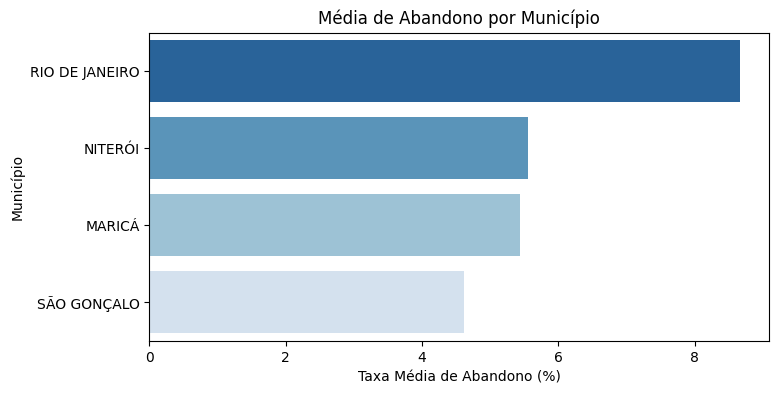

In [11]:
#gráfico de média de abandono por município
plt.figure(figsize=(8, 4))
sns.barplot(
    data=abandono_municipio,
    y='Nome_do_Municipio',
    x='Abandono_EM_Total',
    hue='Nome_do_Municipio',
    palette='Blues_r',
    legend=False)
plt.title('Média de Abandono por Município')
plt.xlabel('Taxa Média de Abandono (%)')
plt.ylabel('Município')
plt.show()

In [12]:
abandono_por_ano = (
    df.groupby('Ano_do_Censo')['Abandono_EM_Total']
      .mean()
      .reset_index()
)
display(abandono_por_ano)

,Ano_do_Censo,Abandono_EM_Total
0,2015,7.714601
1,2016,13.020000
2,2017,7.467751
3,2018,8.020811
4,2019,10.891086
5,2020,0.602479
6,2021,2.939118
7,2022,9.836364
8,2023,8.336639
9,2024,8.182337


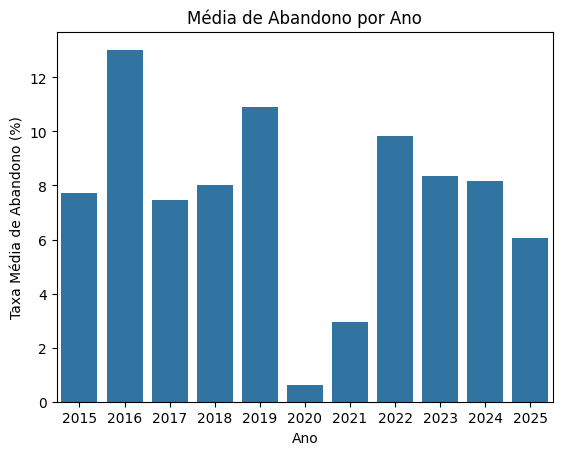

In [13]:
#média de abandono por ano
sns.barplot(abandono_por_ano, x='Ano_do_Censo', y='Abandono_EM_Total' )
plt.title('Média de Abandono por Ano')
plt.xlabel('Ano')
plt.ylabel('Taxa Média de Abandono (%)')
plt.show()

In [14]:
aprovacao_por_ano = (
    df.groupby('Ano_do_Censo')['Aprovacao_EM_Total']
      .mean()
      .reset_index()
)
display(aprovacao_por_ano)

,Ano_do_Censo,Aprovacao_EM_Total
0,2015,75.681818
1,2016,66.609167
2,2017,74.187534
3,2018,73.178378
4,2019,72.383287
5,2020,88.072727
6,2021,90.367218
7,2022,73.779339
8,2023,75.171350
9,2024,75.929076


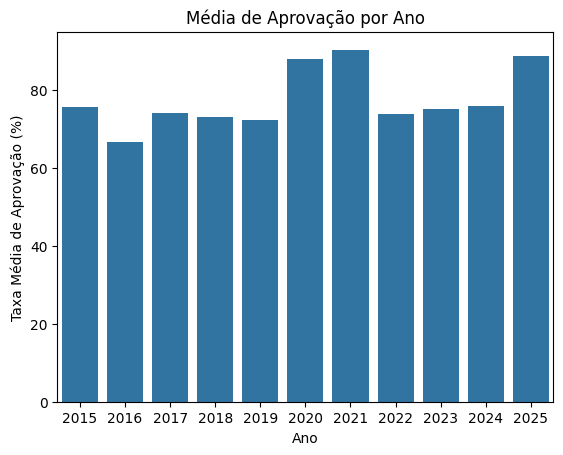

In [15]:
#média de aprovação por ano
sns.barplot(aprovacao_por_ano, x='Ano_do_Censo', y='Aprovacao_EM_Total' )
plt.title('Média de Aprovação por Ano')
plt.xlabel('Ano')
plt.ylabel('Taxa Média de Aprovação (%)')
plt.show()

In [16]:
#checando quantos registros temos por município
df['Nome_do_Municipio'].value_counts()

,count
Nome_do_Municipio,
RIO DE JANEIRO,2795
SÃO GONÇALO,729
NITERÓI,382
MARICÁ,103


In [17]:
reprovacao_por_ano = (
    df.groupby('Ano_do_Censo')['Reprovacao_EM_Total']
      .mean()
      .reset_index()
)
display(reprovacao_por_ano)

,Ano_do_Censo,Reprovacao_EM_Total
0,2015,16.603581
1,2016,20.370833
2,2017,18.344715
3,2018,18.800811
4,2019,16.725627
5,2020,11.324793
6,2021,6.693664
7,2022,16.384298
8,2023,16.492011
9,2024,15.888587


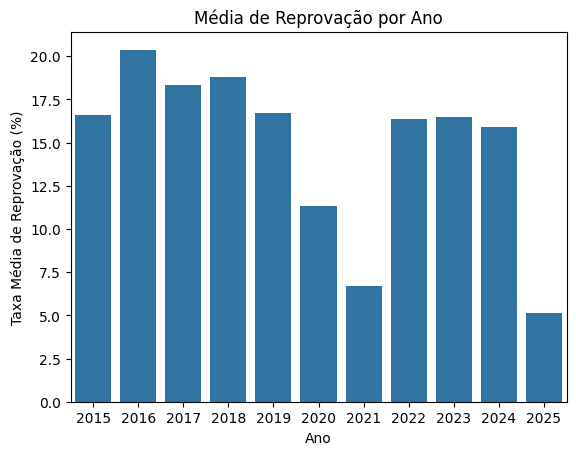

In [18]:
#média de aprovação por ano
sns.barplot(reprovacao_por_ano, x='Ano_do_Censo', y='Reprovacao_EM_Total' )
plt.title('Média de Reprovação por Ano')
plt.xlabel('Ano')
plt.ylabel('Taxa Média de Reprovação (%)')
plt.show()

,Nome_do_Municipio,Ano_do_Censo,Abandono_EM_Total,Reprovacao_EM_Total,Aprovacao_EM_Total
0,MARICÁ,2015,5.325000,14.587500,80.087500
1,MARICÁ,2016,13.062500,12.212500,74.725000
2,MARICÁ,2017,2.688889,15.655556,81.655556
3,MARICÁ,2018,3.633333,13.866667,82.500000
4,MARICÁ,2019,6.800000,19.344444,73.855556
5,MARICÁ,2020,0.170000,3.180000,96.650000
6,MARICÁ,2021,1.360000,9.670000,88.970000
7,MARICÁ,2022,7.510000,12.940000,79.550000
8,MARICÁ,2023,8.170000,13.600000,78.230000
9,MARICÁ,2024,6.420000,17.680000,75.900000


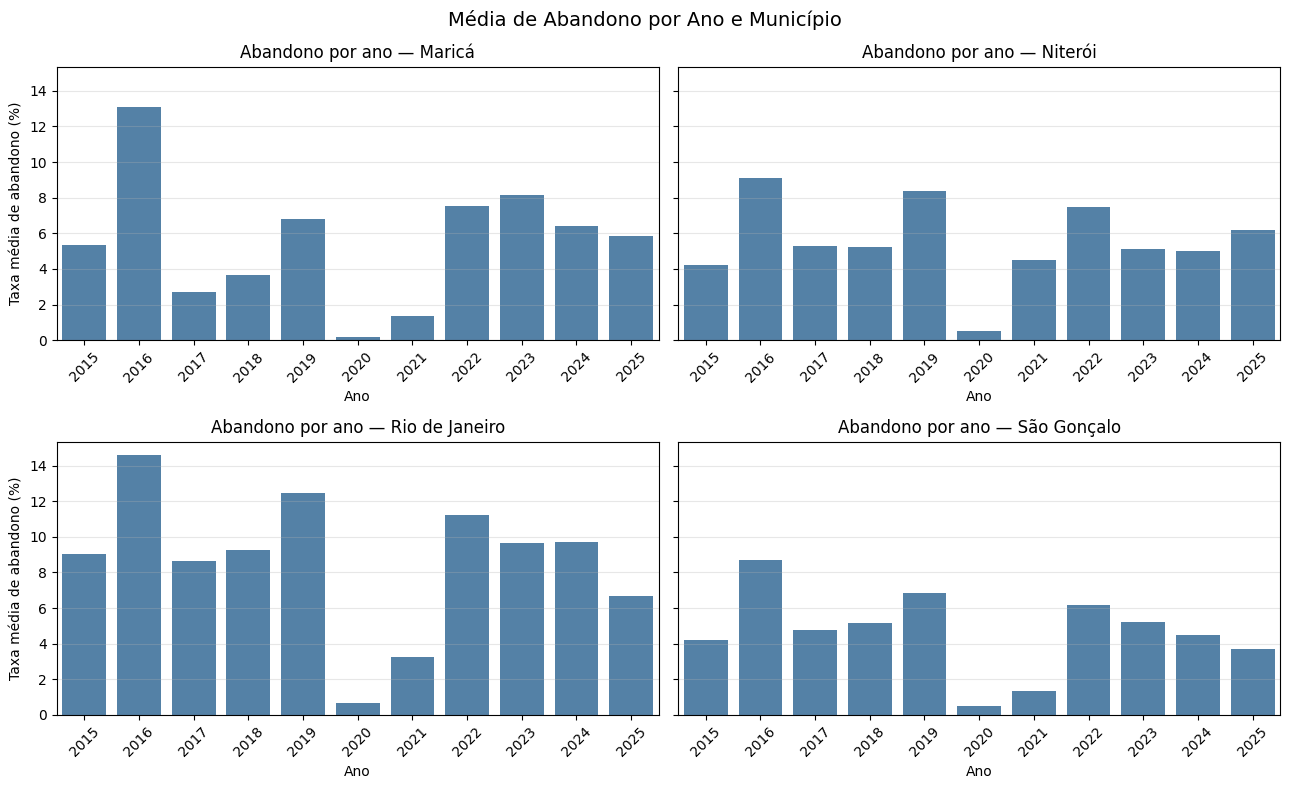

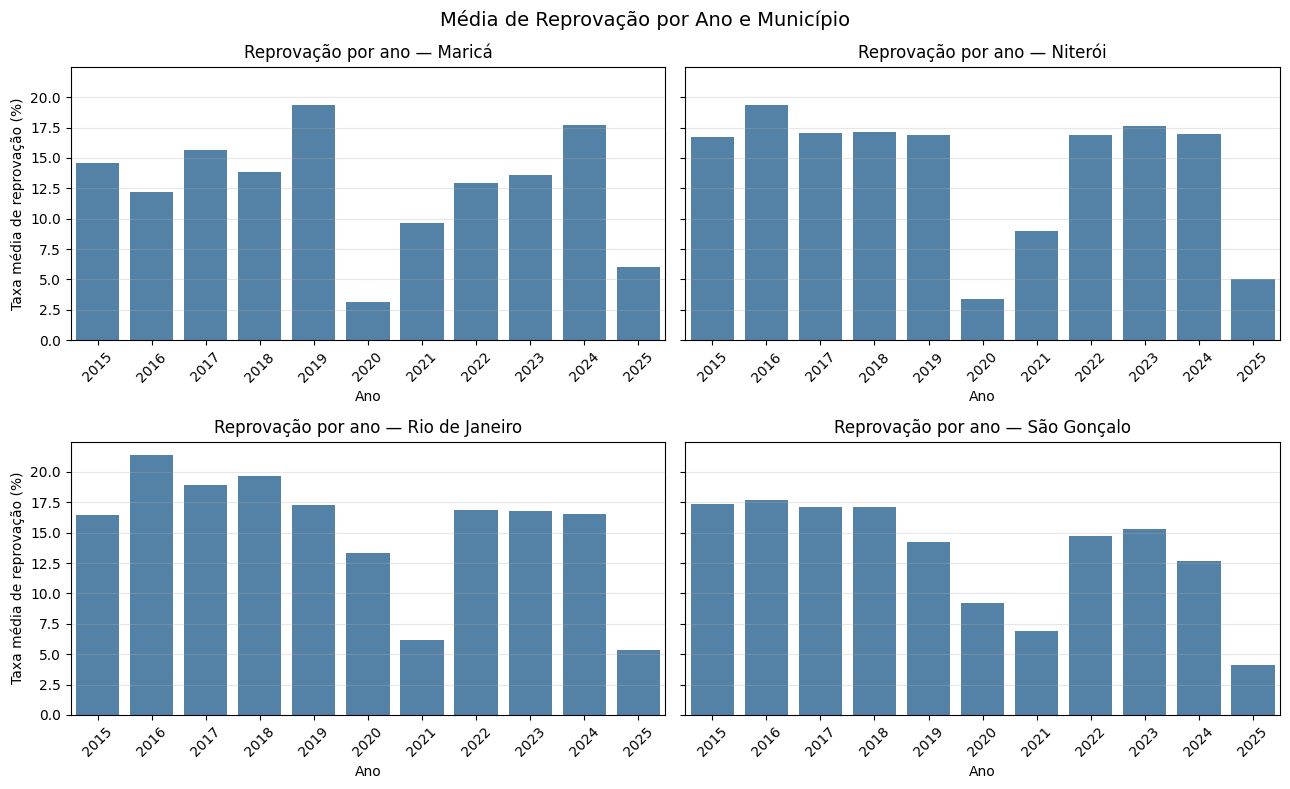

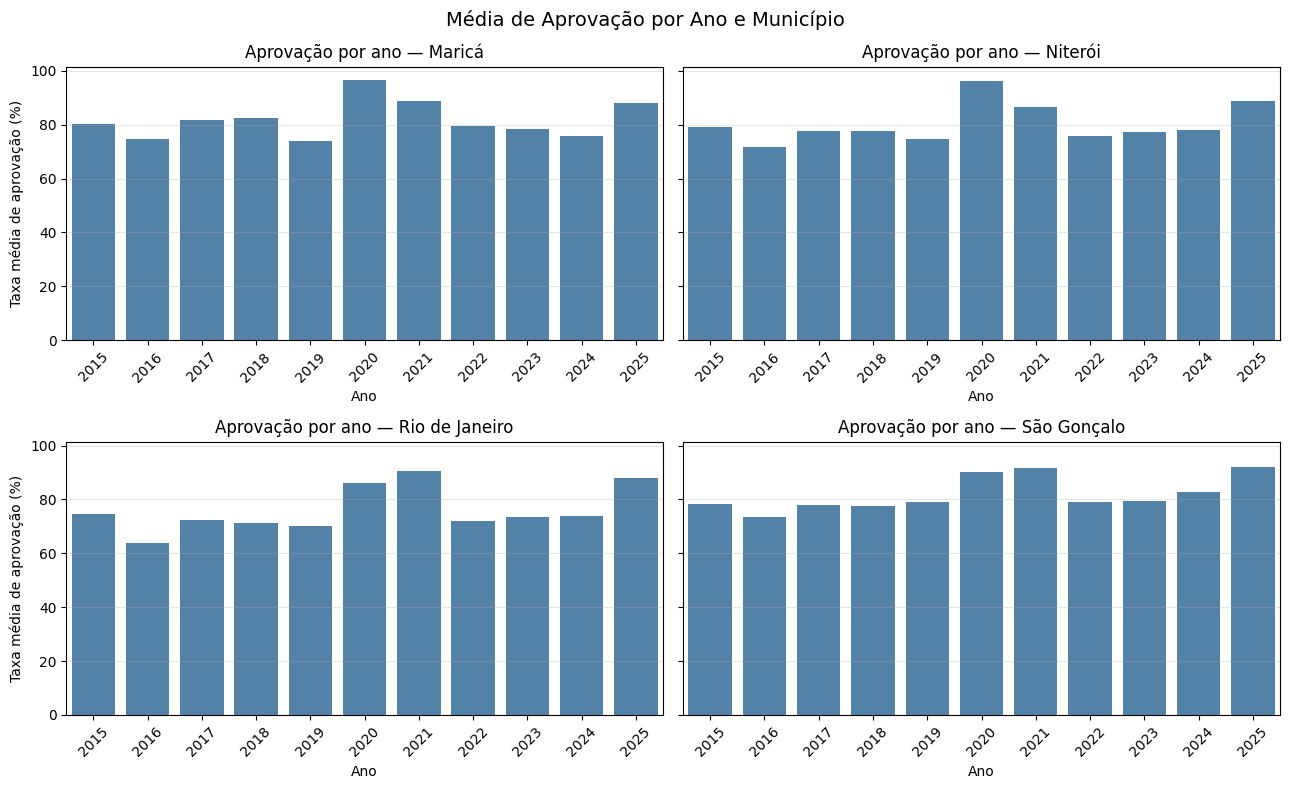

In [19]:
# Médias por município e ano
indicadores = {
    'Abandono_EM_Total': 'Abandono',
    'Reprovacao_EM_Total': 'Reprovação',
    'Aprovacao_EM_Total': 'Aprovação'
}

media_cidade_ano = (
    df.groupby(['Nome_do_Municipio', 'Ano_do_Censo'])[list(indicadores)]
      .mean()
      .reset_index()
)
display(media_cidade_ano)

# Um painel 2x2 (uma cidade por quadro) para cada indicador
def grafico_por_cidade(coluna):
    nome = indicadores[coluna]
    cidades = sorted(media_cidade_ano['Nome_do_Municipio'].unique())
    fig, eixos = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
    for ax, cidade in zip(eixos.flatten(), cidades):
        dados = media_cidade_ano[media_cidade_ano['Nome_do_Municipio'] == cidade]
        sns.barplot(data=dados, x='Ano_do_Censo', y=coluna, color='steelblue', ax=ax)
        ax.set_title(f'{nome} por ano — {cidade.title().replace(" De ", " de ")}')
        ax.set_xlabel('Ano')
        ax.set_ylabel(f'Taxa média de {nome.lower()} (%)')
        ax.tick_params(axis='x', rotation=45)
        ax.grid(axis='y', alpha=0.3)
    plt.suptitle(f'Média de {nome} por Ano e Município', fontsize=14)
    plt.tight_layout()
    plt.show()

for coluna in indicadores:
    grafico_por_cidade(coluna)